# Homework 3


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

## Dataset

In [2]:
#!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

## Data preparation


### Import dataset

In [3]:
df = pd.read_csv("course_lead_scoring_2026.csv")

### Check missing values

In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

### Impute missing values

In [5]:
df_clean = df

In [6]:
mask_cat = df_clean.dtypes == 'str'
mask_num = df_clean.dtypes != 'str'

In [7]:
categorical = list(df_clean.dtypes[mask_cat].index)
numerical = list(df_clean.dtypes[mask_num].index)

In [8]:
print("cat", categorical)
print('num : ', numerical)

cat ['lead_source', 'industry', 'employment_status', 'location']
num :  ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']


In [9]:
df_clean[categorical] = df_clean[categorical].fillna("NA")
df_clean[numerical] = df_clean[numerical].fillna(0.0)

## Question 1


In [10]:
df_clean.industry.mode()

0    technology
Name: industry, dtype: str

## Question 2


In [11]:
df_num = df_clean[numerical]

In [12]:
corr_matrix = df_num.corr()

In [13]:
corr_matrix

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


<Axes: >

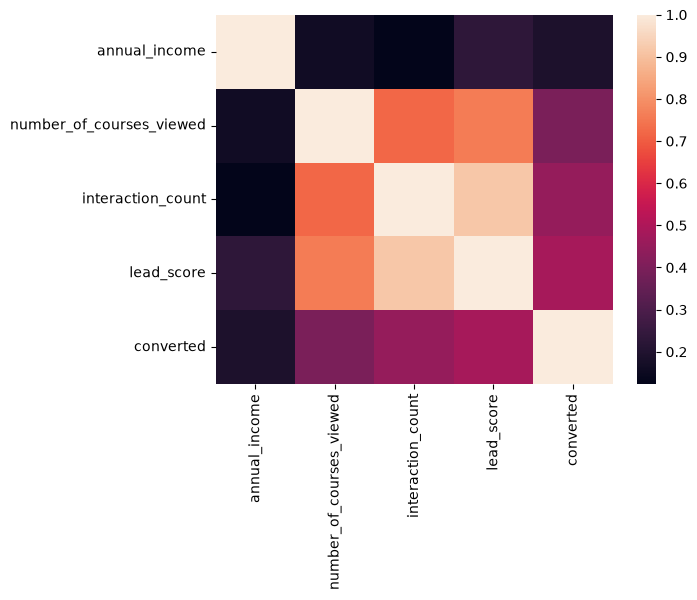

In [14]:
sns.heatmap(corr_matrix)

# Split the data

In [15]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [16]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [17]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [18]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [19]:
y_train[:5]

array([1, 0, 1, 0, 1])

## Question 3


In [22]:
for item in categorical:
    mutual_info = mutual_info_score(df_full_train[item], df_full_train.converted)
    print(item, " : ", round(mutual_info, 2))

lead_source  :  0.03
industry  :  0.0
employment_status  :  0.02
location  :  0.0


## Question 4


In [25]:
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,finance,employed,asia,65980.0,2,3,0.37
1,events,finance,employed,south_america,71662.0,0,0,0.09
2,referral,NA,employed,asia,40220.0,2,5,0.55
3,organic_search,finance,employed,north_america,88352.0,2,2,0.45
4,events,technology,employed,north_america,89316.0,1,5,0.00


In [30]:
dv = DictVectorizer(sparse=False)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [33]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

In [34]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [35]:
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

In [40]:
y_pred = model.predict(X_val)

### Evaluation

In [43]:
accuracy = accuracy_score(y_pred, y_val)
print(round(accuracy, 2))

0.65


## Question 5


In [73]:
accuracy

0.645

In [76]:
features = list(df_train.columns)
for f in features:
    liste = list(df_train.columns)
    liste.remove(f)
    dv = DictVectorizer(sparse=False)
    train_dict = df_train[liste].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    val_dict = df_val[liste].to_dict(orient='records')
    X_val = dv.transform(val_dict)
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    score = accuracy_score(y_pred, y_val)
    print(f, " : ", "difference : ", accuracy-score)


lead_source  :  difference :  0.0030000000000000027
industry  :  difference :  0.0
employment_status  :  difference :  0.0
location  :  difference :  0.0
annual_income  :  difference :  -0.07899999999999996
number_of_courses_viewed  :  difference :  0.0020000000000000018
interaction_count  :  difference :  0.04400000000000004
lead_score  :  difference :  0.0010000000000000009


## Question 6

In [82]:
dv = DictVectorizer(sparse=False)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [83]:
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

In [84]:
for c in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    score = accuracy_score(y_pred, y_val)
    print(c, " : ", "Score : ", round(score, 3))
    

1e-06  :  Score :  0.598
1e-05  :  Score :  0.598
0.0001  :  Score :  0.613
0.001  :  Score :  0.645
